# Karadeniz Ereğli Hava Kalitesi — Veri Hazırlama

Bu projede Karadeniz Ereğli’deki hava kalitesi ölçümlerinden ertesi günün PM2.5 AQI değerini tahmin ediyoruz. AQI yükseldikçe hava kalitesi düşer.

Kaynaklar: [World Air Quality Index](https://aqicn.org/historical/#!city:turkey/karadeniz/zonguldak-karadeniz-eregli), [Ulusal Hava Kalite İzleme Ağı](https://www.turkiye.gov.tr/cevre-ve-sehircilik-ulusal-hava-kalite-izleme-agi)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Raw Data

In [2]:
raw_path = Path("data/raw/zonguldak-karadeniz eregli, turkey-air-quality.csv")
df = pd.read_csv(raw_path)

date: Günlük kaydın tarihi. 

pm25: İnce parçacıklara (PM2.5) ait günlük AQI puanı. 

pm10: PM10 parçacıklarına ait günlük AQI puanı. 

o3: Ozona (O₃) ait günlük AQI puanı. 

no2: Azot dioksite (NO₂) ait günlük AQI puanı. 

so2: Kükürt dioksite (SO₂) ait günlük AQI puanı. 

co: Karbonmonoksite (CO) ait günlük AQI puanı. 

In [3]:
df.head() 

,date,pm25,pm10,o3,no2,so2,co
0,2026/11/1,62,,,,,
1,2026/10/1,56,32,,11,,9
2,2026/10/2,54,33,,11,,9
3,2026/10/3,55,32,,8,,9
4,2026/10/4,54,28,,14,,9


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3771 entries, 0 to 3770
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   date    3771 non-null   str  
 1    pm25   3771 non-null   str  
 2    pm10   3771 non-null   str  
 3    o3     3771 non-null   str  
 4    no2    3771 non-null   str  
 5    so2    3771 non-null   str  
 6    co     3771 non-null   str  
dtypes: str(7)
memory usage: 206.4 KB


## Veri hazırlama

In [5]:
df.columns = df.columns.str.strip()
df = df.replace(r"^\s*$", np.nan, regex=True)
df["date"] = pd.to_datetime(df["date"], errors="coerce")

numeric_columns = ["pm25", "pm10", "o3", "no2", "so2", "co"]
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors="coerce")

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3771 entries, 0 to 3770
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    3771 non-null   datetime64[us]
 1   pm25    2273 non-null   float64       
 2   pm10    3142 non-null   float64       
 3   o3      3289 non-null   float64       
 4   no2     2736 non-null   float64       
 5   so2     3127 non-null   float64       
 6   co      3349 non-null   float64       
dtypes: datetime64[us](1), float64(6)
memory usage: 206.4 KB


In [7]:
yearly_groups = df.groupby(df["date"].dt.year.rename("year"))

yearly_missing = yearly_groups[numeric_columns].apply(
    lambda group: group.isna().sum()
)
yearly_missing.insert(0, "toplam_kayit", yearly_groups.size())

yearly_missing

,toplam_kayit,pm25,pm10,o3,no2,so2,co
year,,,,,,,
2013,1,1,1,0,0,0,0
2014,260,260,8,6,50,29,20
2015,363,363,1,2,9,63,33
2016,311,311,45,3,17,142,65
2017,261,261,65,6,6,34,66
2018,172,163,20,6,6,30,20
2019,64,1,4,6,20,16,8
2020,332,20,118,4,60,9,78
2021,355,29,217,69,49,21,23


2020 öncesinde parçacık ölçümleri düzensiz ve eksik. 2023’te ise NO₂ ölçümü bulunmadığı için 2020 ve sonrasını alıp NO₂ sütununu çıkarıyoruz.

In [8]:
df = df.loc[df["date"].dt.year >= 2020].drop(columns="no2").reset_index(drop=True)
numeric_columns = ["pm25", "pm10", "o3", "so2", "co"]

In [9]:
df.isna().sum()

date      0
pm25    138
pm10    485
o3      453
so2     330
co      210
dtype: int64

In [10]:
pollutants = df[numeric_columns]
q1 = pollutants.quantile(0.25)
q3 = pollutants.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = pollutants.lt(lower_bound) | pollutants.gt(upper_bound)

iqr_summary = pd.DataFrame({
    "Alt sınır (AQI)": lower_bound,
    "Üst sınır (AQI)": upper_bound,
    "Aykırı ölçüm": outliers.sum(),
}).rename(index={
    "pm25": "PM2.5", "pm10": "PM10", "o3": "O₃", "so2": "SO₂", "co": "CO",
})

iqr_summary.rename_axis("Kirletici")

,Alt sınır (AQI),Üst sınır (AQI),Aykırı ölçüm
Kirletici,,,
PM2.5,-8.5,123.5,108
PM10,-7.0,89.0,42
O₃,-14.0,42.0,87
SO₂,-1.5,10.5,112
CO,-5.0,19.0,121


## Keşifsel veri analizi

In [11]:
df[numeric_columns].agg(["count", "mean", "median", "std", "min", "max"]).T

,count,mean,median,std,min,max
pm25,2201.0,60.533394,55.0,30.571048,5.0,219.0
pm10,1854.0,43.207120,39.0,29.684166,2.0,577.0
o3,1886.0,17.449099,12.0,28.347246,1.0,500.0
so2,2009.0,5.087606,5.0,3.086452,1.0,29.0
co,2129.0,7.682480,6.0,6.250765,1.0,38.0


In [12]:
df[numeric_columns].skew()

pm25     1.082298
pm10     8.501545
o3      11.304939
so2      2.063682
co       2.026646
dtype: float64

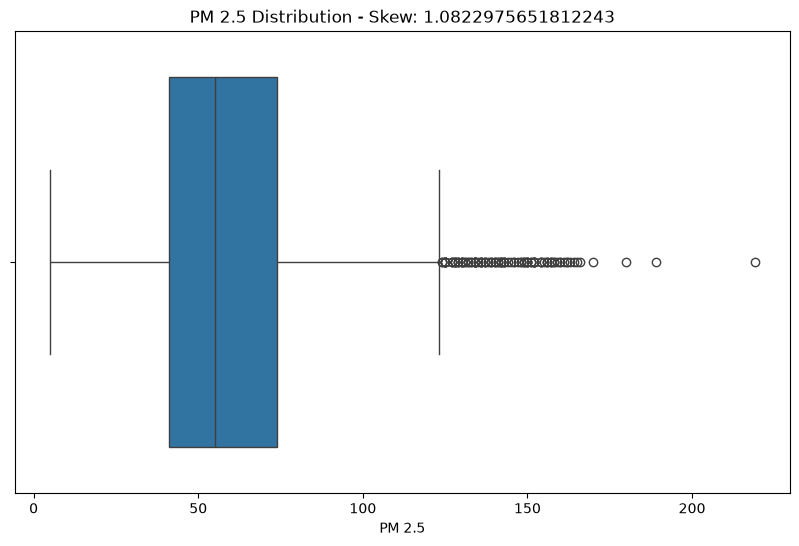

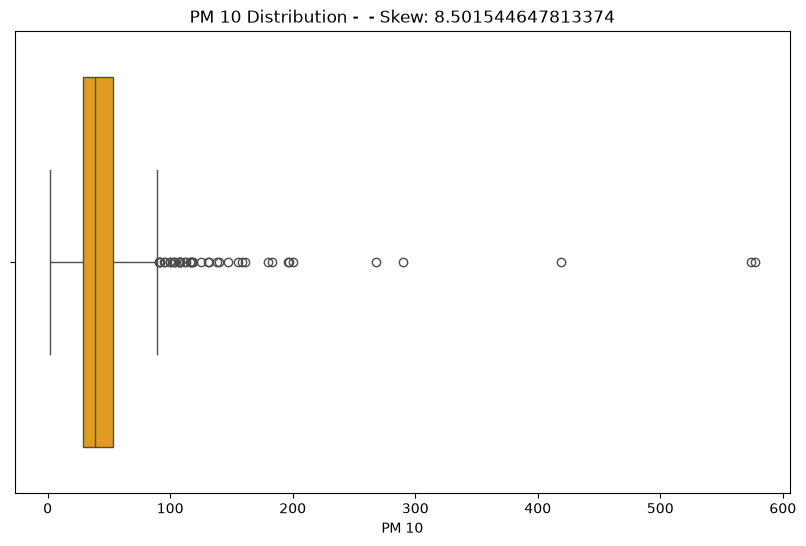

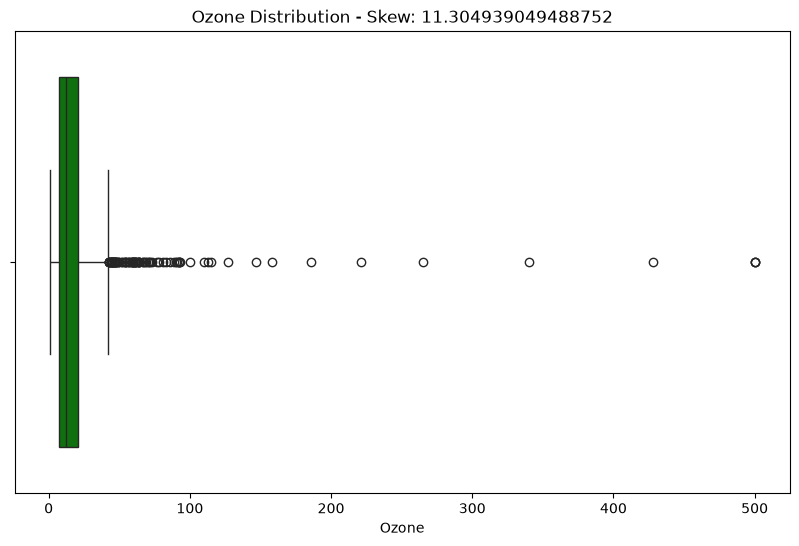

In [13]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="pm25")
plt.title(f"PM 2.5 Distribution - Skew: {df["pm25"].skew()}")
plt.xlabel("PM 2.5")
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="pm10", color="orange")
plt.title(f"PM 10 Distribution -  - Skew: {df["pm10"].skew()}")
plt.xlabel("PM 10")
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="o3", color="green")
plt.title(f"Ozone Distribution - Skew: {df["o3"].skew()}")
plt.xlabel("Ozone")
plt.show()

## Hazırlanan veriyi kaydetme

In [14]:
processed_path = Path("data/processed/eregli_air_quality.csv")
processed_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(processed_path, index=False)

print(f"{len(df)} kayıt kaydedildi: {processed_path}")

2339 kayıt kaydedildi: data\processed\eregli_air_quality.csv
